In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import warnings


warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


In [3]:
#open pickle
with open('/Users/blancamartin/Desktop/Muotri_lab/MAOA_pickles/processed_df.pkl', 'rb') as file:
    big_df = pickle.load(file)

In [4]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [5]:
#remove day sept 26th (bad recording)

#remove bad experiment 
# Convert recording_date safely
big_df["recording_date"] = pd.to_datetime(big_df["recording_date"], errors="coerce")

# Remove all recordings from Sept 26, 2025
remove_date = pd.to_datetime("2025-09-26")
big_df = big_df[big_df["recording_date"] != remove_date]

#### Mutant (c3, c71, c90), WT (c12, c30, c54) and GM

In [6]:
#Remove lines we are not using 
REMOVALS = {
    "MAOA1":{"H9", "C12", "C3", "C54","C71"},
    "MAOA2":{"H9", "C12", "C3", "C54","C71"},
    "MAOA3":{"H9", "C12", "C3", "C54","C71"},
    "MAOA72": {"C12", "C3", "C54", "C71"},
    "MAOA76": {"C12", "C3", "C54", "C71"},
    "MAOA77": {"C12", "C3", "C54", "C71"},
}

In [7]:
big_df = remove_clones_by_plate(big_df, REMOVALS)

Removed 516 rows based on plate-specific clone removal.


In [8]:
big_df

,well,firing_rate_stats_hz,burst_rate_stats_hz,network_event_rate_hz,synchrony_index,electrodes,firing_rate_vector_hz,burst_rate_vector_hz,recording_date,recording_date_str,plate_name,cell_line,organoid_age_days,spike_list_path,experiment
0,A2,"[1.4391208230357608, 1.6648439676442284]","[0.09436092897565711, 0.09586305971365496]",0.124031,0.022132,"[A2_11, A2_12, A2_13, A2_14, A2_15, A2_16, A2_...","[3.015680429868851, 0.0006597419448411399, 0.0...","[0.19066542205908946, nan, nan, nan, 0.0032987...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
1,A3,"[0.4052027312243695, 0.5762036681376207]","[0.018160265113258748, 0.024168885783248578]",0.003299,0.000282,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[nan, 0.0006597419448411399, 0.000659741944841...","[nan, nan, nan, nan, 0.00791690333809368, nan,...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
2,A4,"[0.5015034617690537, 0.8086074177045918]","[0.035769487183343544, 0.05082674212974362]",0.056738,0.003155,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.13260813091306914, 0.0006597419448411399, 0...","[0.008576645282934819, nan, nan, nan, 0.003298...",2025-04-14,04.14.2025,MAOA2,C90,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
3,B2,"[1.821286102520696, 3.2362072623431377]","[0.1274676415928486, 0.11408226907420285]",0.148442,0.013659,"[B2_11, B2_12, B2_13, B2_14, B2_15, B2_16, B2_...","[0.0013194838896822799, 3.5289596629552578, 0....","[nan, 0.20188103512138883, nan, nan, 0.0936833...",2025-04-14,04.14.2025,MAOA2,C30,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
4,B3,"[0.7793130012355004, 1.3467926472630483]","[0.058214372561458665, 0.07832226183330862]",0.078509,0.001454,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[5.249566655100951, 0.0006597419448411399, nan...","[0.17747058316226666, nan, nan, 0.085106710884...",2025-04-14,04.14.2025,MAOA2,GM,73,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
931,A3,"[0.05701119431773227, 0.1535796905411747]","[0.032265241228589356, 0.03379079821952257]",0.000000,0.051877,"[A3_11, A3_12, A3_13, A3_14, A3_15, A3_16, A3_...","[0.07891625880113576, 0.01890702033777211, 0.0...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,C90,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
932,A4,"[0.004241748910561047, 0.009775569618114778]","[nan, nan]",0.000000,0.232831,"[A4_11, A4_12, A4_13, A4_14, A4_15, A4_16, A4_...","[0.0008220443625118308, nan, 0.000822044362511...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
933,B3,"[0.18866972022675382, 0.5198453411082501]","[0.03605251704159029, 0.0311337640259423]",0.000000,0.067674,"[B3_11, B3_12, B3_13, B3_14, B3_15, B3_16, B3_...","[1.6054526399856057, 0.0008220443625118308, 0....","[0.027127463962890418, nan, nan, nan, 0.023839...",2025-10-30,10.30.2025,MAOA76,C90,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3
934,B4,"[0.010609510053668317, 0.045617147944364]","[0.01808497597526028, 0.0]",0.000000,-0.001633,"[B4_11, B4_12, B4_13, B4_14, B4_15, B4_16, B4_...","[0.004932266175070985, 0.0008220443625118308, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2025-10-30,10.30.2025,MAOA76,GM,259,/Users/blancamartin/Downloads/Sandra_MAOA_MEA/...,Exp3


### Exp 3 analysis for Paper Figure

In [9]:
# Updated palette using the specific genetic strings as keys
MAOA_FIGURE_PALETTE = {
    "Xa:WT/Xi:MUT": "#9C899C", # Pink/grey (Ctrl)
    "Xa:MUT/Xi:WT": "#EAC3EB", # Light pink (Mut)
    "MAOA/B−/Y":    "#E980C0"  # Dark pink (GM)
}


PLOT_ORDER = ["Xa:WT/Xi:MUT", "Xa:MUT/Xi:WT", "MAOA/B−/Y"]


FEATURE: FIRING
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


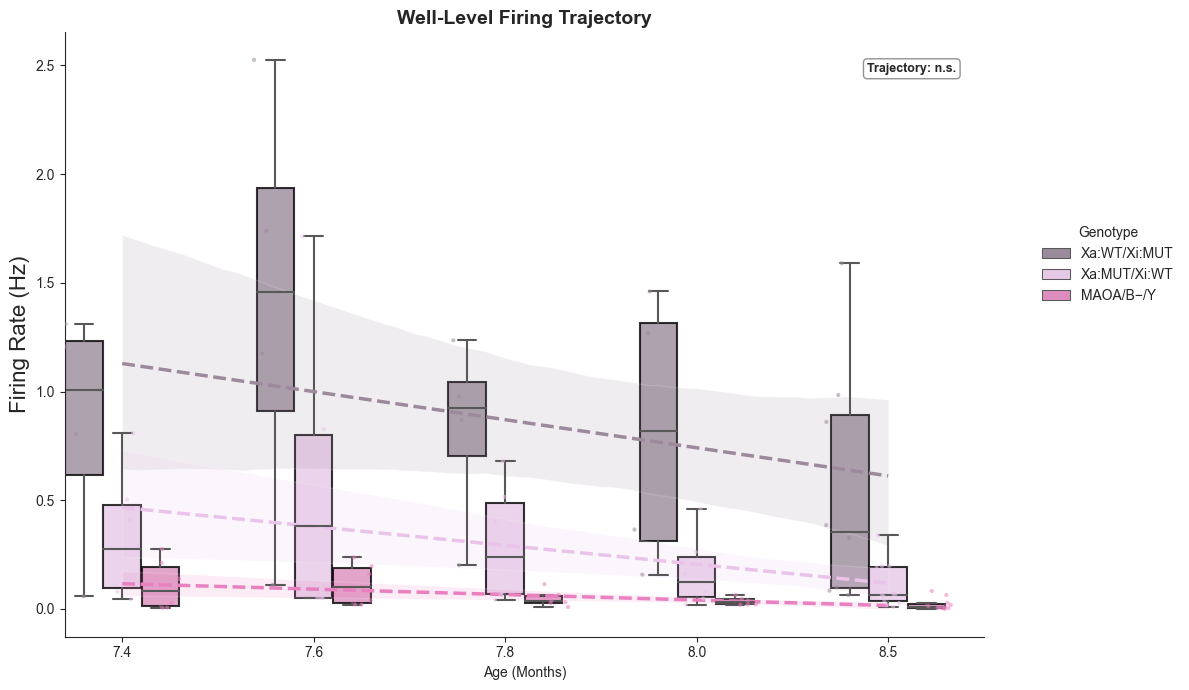

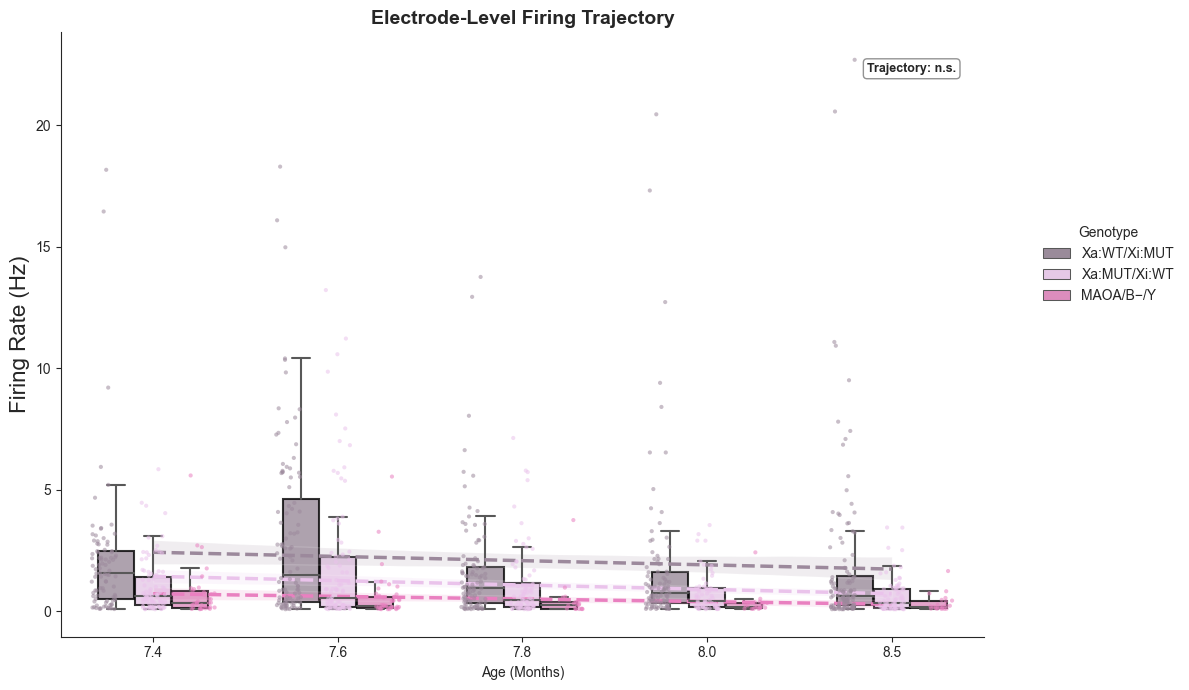


Trajectory ANOVA (Interaction):
                          sum_sq    df          F        PR(>F)
C(group)               8.765318   2.0  31.134685  9.320358e-11
C(time_val)            1.933233   4.0   3.433452  1.208469e-02
C(group):C(time_val)   0.937174   8.0   0.832218  5.768818e-01
Residual              11.401926  81.0        NaN           NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.016213                             0.5144                             0.0131                                0.0828
  7.6 0.028082                             0.4567                             0.0222                                0.1563
  7.8 0.002547                             0.2836                             0.0019                                0.0268
  8.0 0.007505                             0.7530                             0.0073                                0.0245
  8.5 0.00

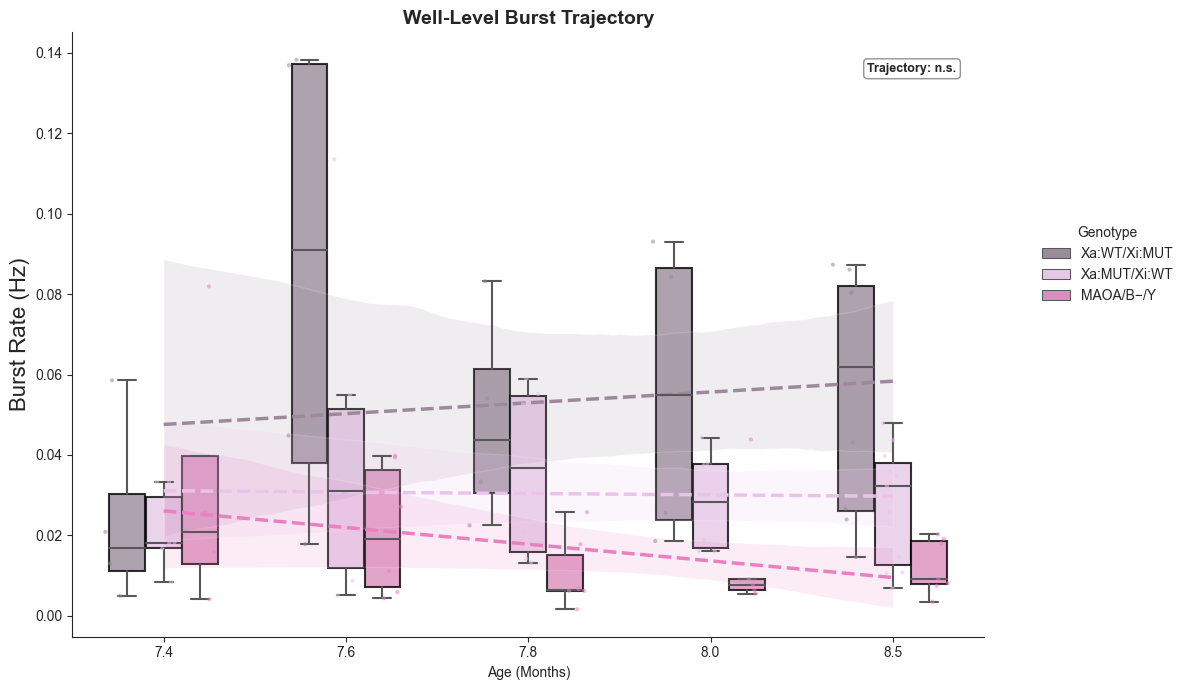

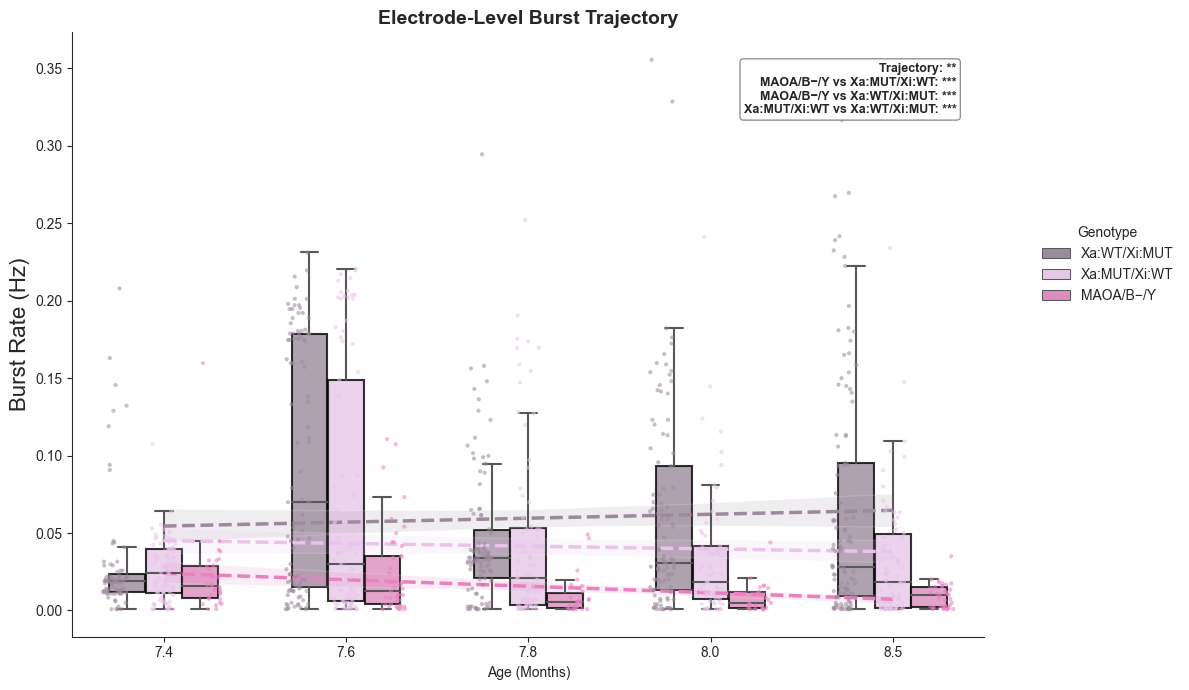


Trajectory ANOVA (Interaction):
                         sum_sq    df          F    PR(>F)
C(group)              0.018433   2.0  13.983767  0.000007
C(time_val)           0.003843   4.0   1.457755  0.224043
C(group):C(time_val)  0.006366   8.0   1.207302  0.307114
Residual              0.047455  72.0        NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.774789                                NaN                                NaN                                   NaN
  7.6 0.085985                                NaN                                NaN                                   NaN
  7.8 0.025308                             0.1030                             0.0269                                0.5989
  8.0 0.061790                                NaN                                NaN                                   NaN
  8.5 0.001237                     

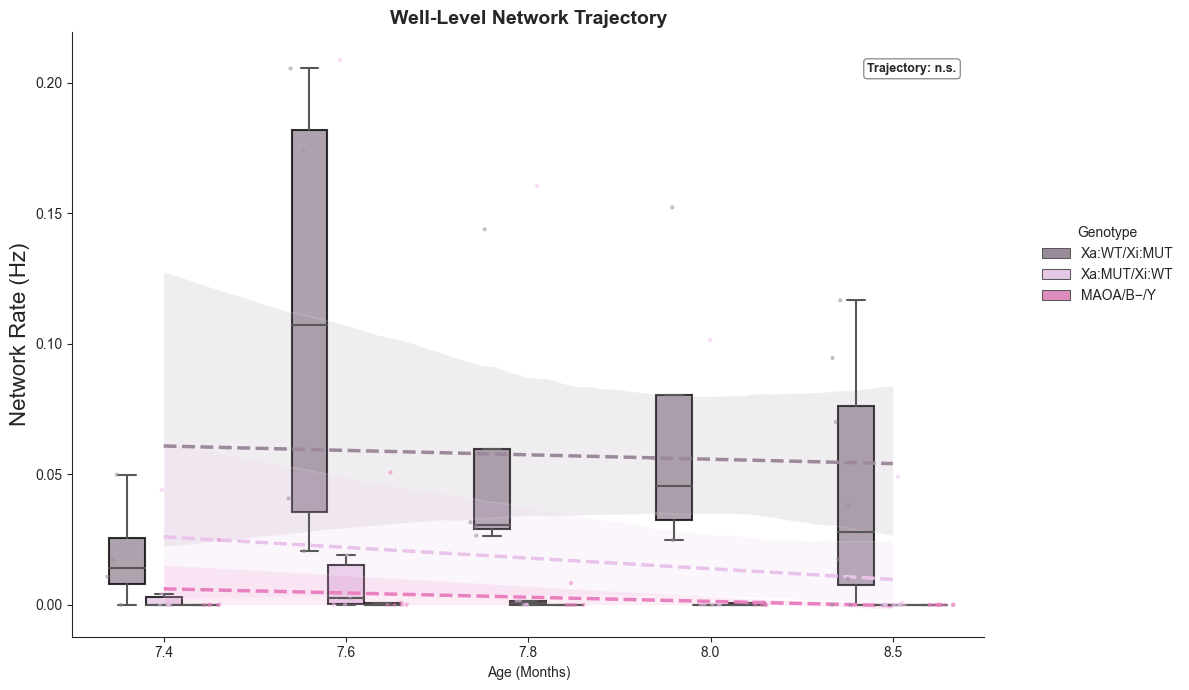


Trajectory ANOVA (Interaction):
                         sum_sq    df          F    PR(>F)
C(group)              0.044093   2.0  13.438953  0.000009
C(time_val)           0.014317   4.0   2.181752  0.078325
C(group):C(time_val)  0.010790   8.0   0.822156  0.585401
Residual              0.132880  81.0        NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.361415                                NaN                                NaN                                   NaN
  7.6 0.112603                                NaN                                NaN                                   NaN
  7.8 0.237107                                NaN                                NaN                                   NaN
  8.0 0.049007                             0.7339                             0.0431                                0.1409
  8.5 0.000859                     

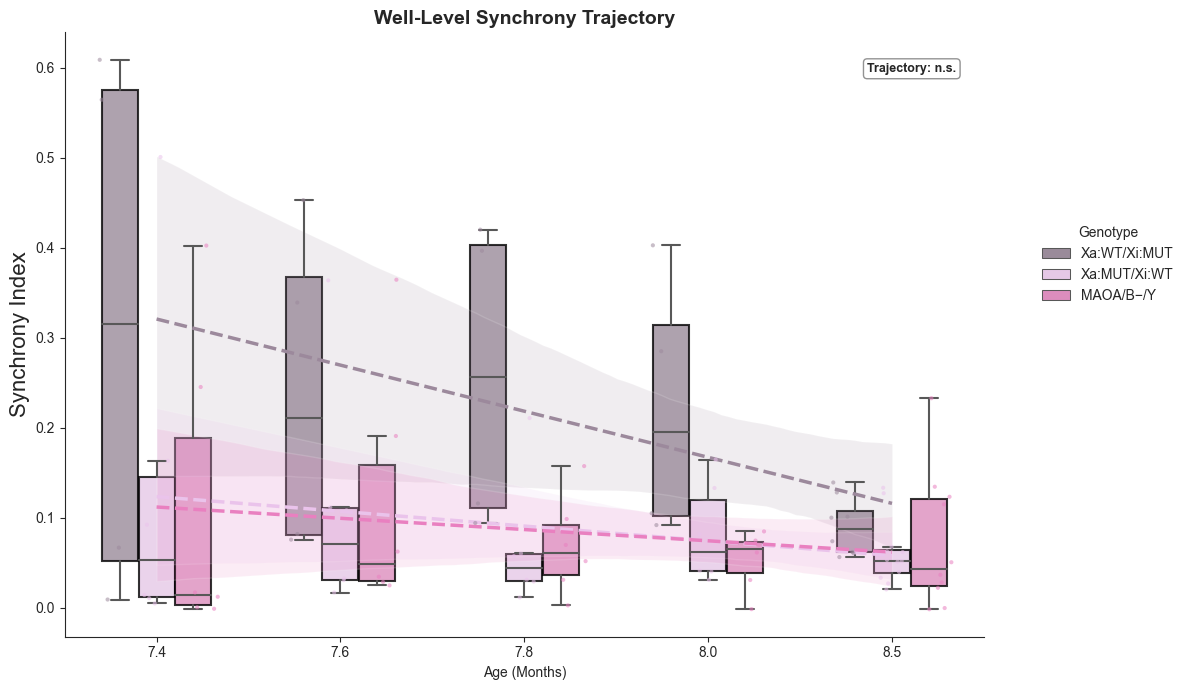


Trajectory ANOVA (Interaction):
                         sum_sq    df         F    PR(>F)
C(group)              0.248424   2.0  8.092525  0.000635
C(time_val)           0.120986   4.0  1.970592  0.107073
C(group):C(time_val)  0.091689   8.0  0.746699  0.650184
Residual              1.212570  79.0       NaN       NaN

Time-Point Comparisons:
  Time  ANOVA_p  MAOA/B−/Y vs Xa:MUT/Xi:WT (p-adj)  MAOA/B−/Y vs Xa:WT/Xi:MUT (p-adj)  Xa:MUT/Xi:WT vs Xa:WT/Xi:MUT (p-adj)
  7.4 0.353721                                NaN                                NaN                                   NaN
  7.6 0.380261                                NaN                                NaN                                   NaN
  7.8 0.021854                             0.9994                             0.0328                                0.0311
  8.0 0.019603                             0.8206                             0.0192                                0.0519
  8.5 0.468556                          

In [10]:
# You can pass your custom palette directly
my_stats = run_mea_analysis_for_figure(
    big_df, 
    experiment='Exp3', unit = "months",
    palette=MAOA_FIGURE_PALETTE
)


--- GENERATING GROUPED PLOTS FOR FIRING ---


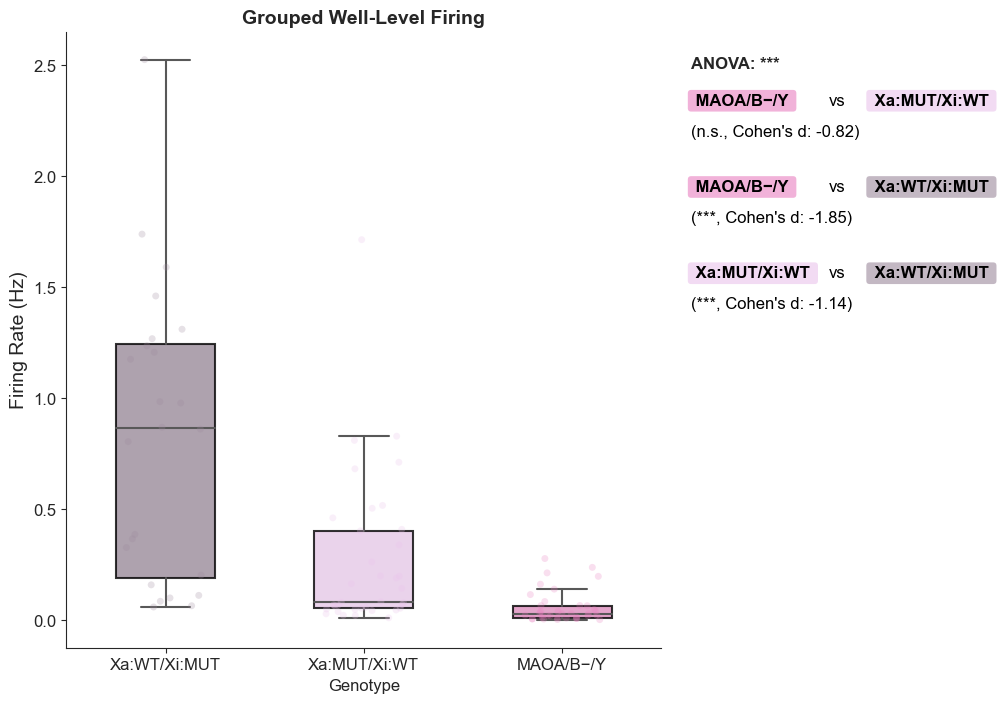

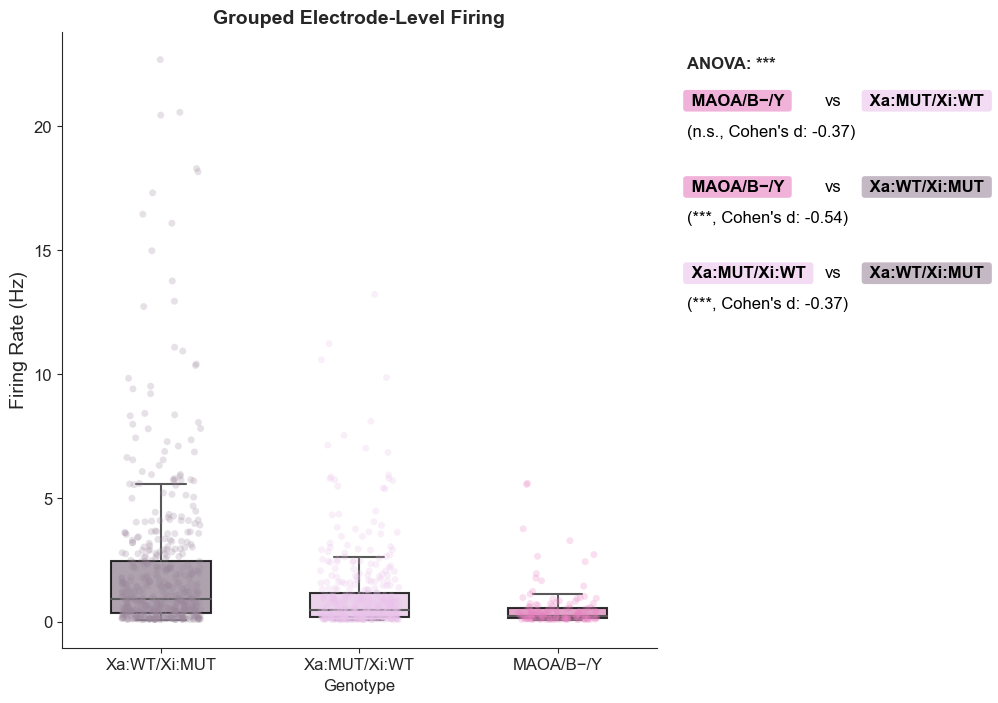


--- GENERATING GROUPED PLOTS FOR BURST ---


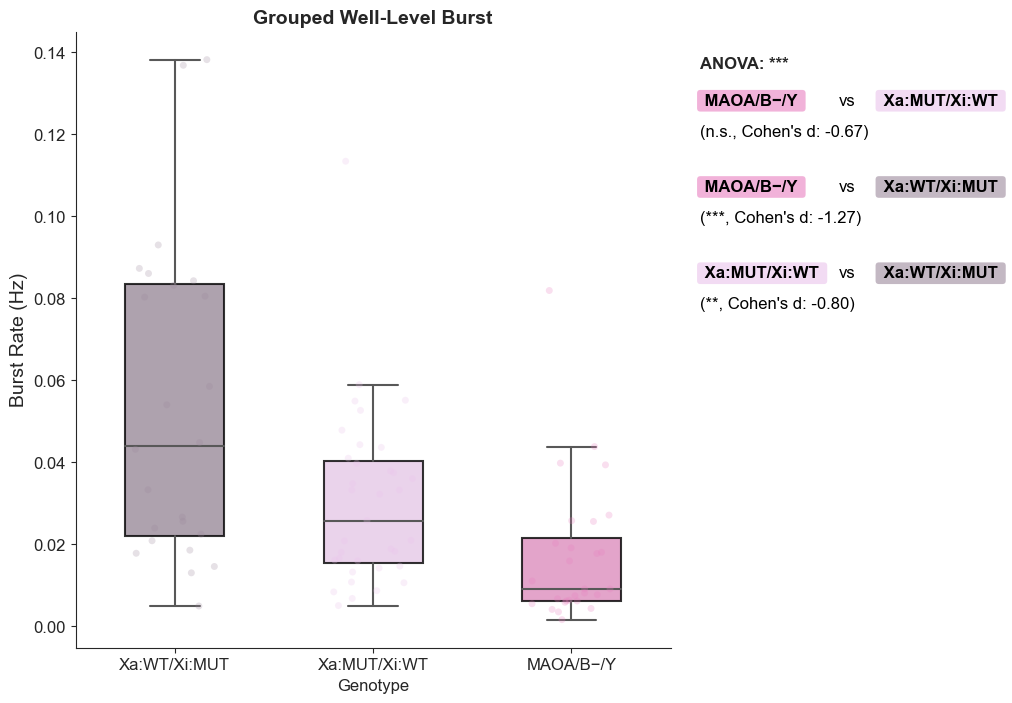

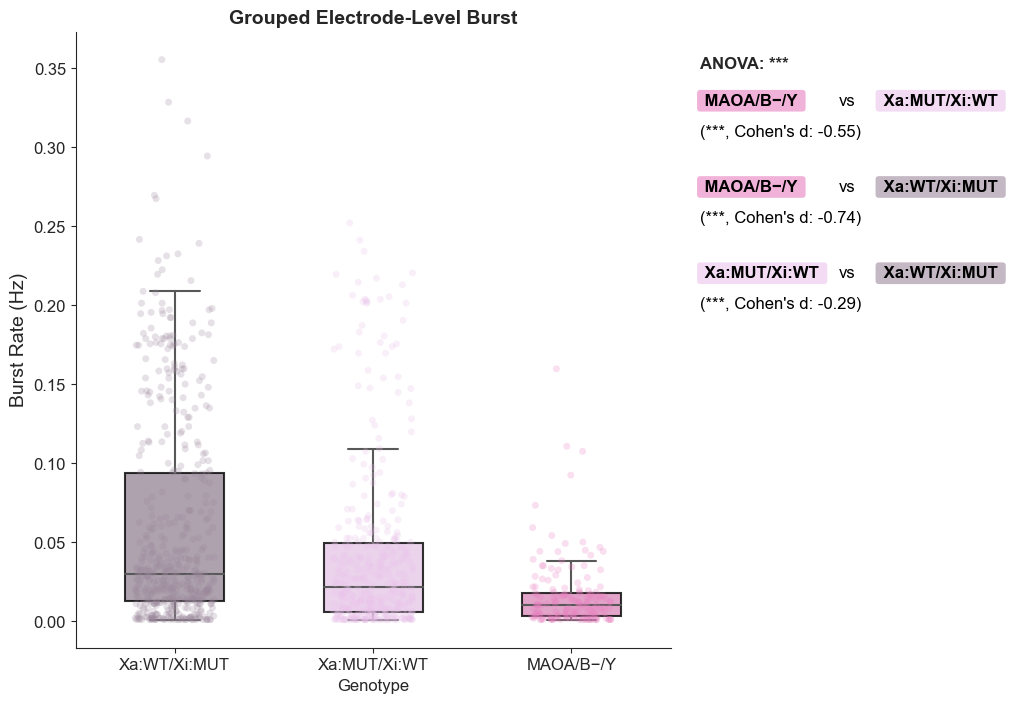


--- GENERATING GROUPED PLOTS FOR NETWORK ---


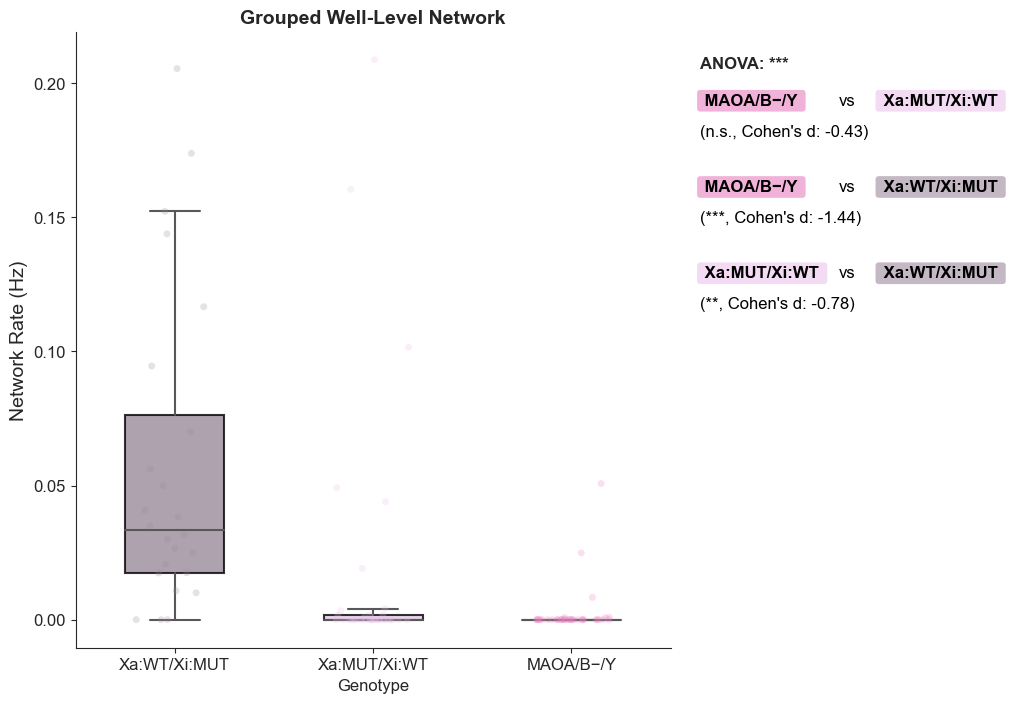


--- GENERATING GROUPED PLOTS FOR SYNCHRONY ---


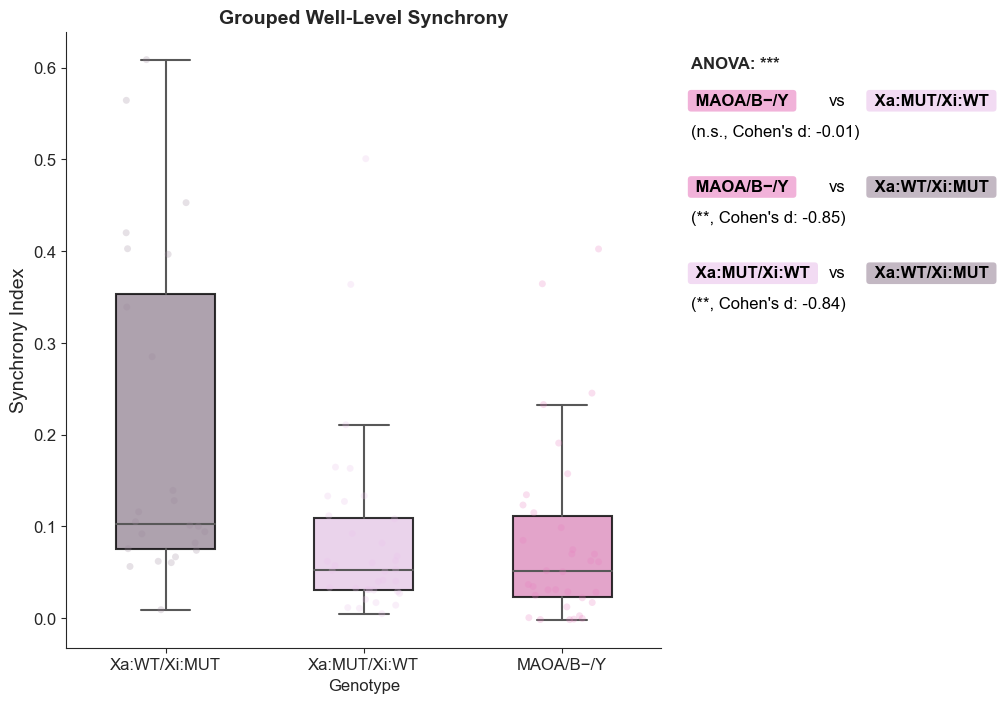

In [11]:



run_grouped_analysis(big_df, "Exp3")